In [2]:
import pandas as pd

df = pd.read_csv('./data/train.csv')

df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


LotFrontage - численное значение, 259 пустых

Alley - строка, 3 уникальных (одно пустое), 1369 пустых

MasVnrType - строка, 4 уникальных (одно пустое), 872 пустых

'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'BsmtFullBath', 'BsmtHalfBath' - есть пустые 37 штук, пустые в одних строках
1) Пердположение: если важны, заменить на строку



In [ ]:
def is_bsmt_fill(x):
    if isinstance(x, str):
        return False
    else:
        return True

df['IsBsmt'] = df['BsmtQual'].apply(is_bsmt_fill)

In [25]:
df.loc[df['BsmtQual'].isna() == False][['Id', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 
                               'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'BsmtFullBath', 'BsmtHalfBath']]

,Id,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,BsmtFullBath,BsmtHalfBath
0,1,Gd,TA,No,GLQ,706,0,150,1,0
1,2,Gd,TA,Gd,ALQ,978,0,284,0,1
2,3,Gd,TA,Mn,GLQ,486,0,434,1,0
3,4,TA,Gd,No,ALQ,216,0,540,1,0
4,5,Gd,TA,Av,GLQ,655,0,490,1,0
...,...,...,...,...,...,...,...,...,...,...
1455,1456,Gd,TA,No,Unf,0,0,953,0,0
1456,1457,Gd,TA,No,ALQ,790,163,589,1,0
1457,1458,TA,Gd,No,GLQ,275,0,877,0,0
1458,1459,TA,TA,Mn,GLQ,49,1029,0,1,0


<Axes: >

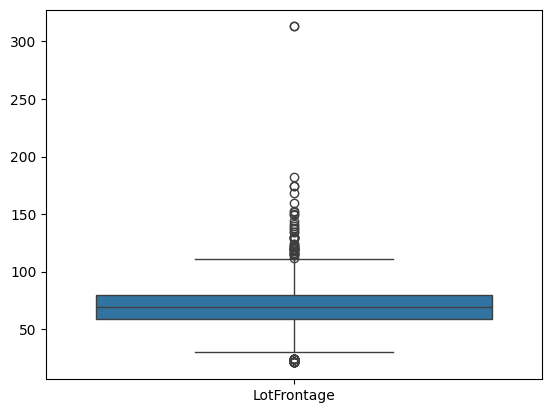

In [29]:
import seaborn as sns

sns.boxplot(df[['LotFrontage', 'LotArea', 'Exterior2nd']])

In [61]:
df['BsmtQual'] = df['BsmtQual'].fillna('Null')

In [62]:
from sklearn.preprocessing import LabelEncoder

encoder_qual = LabelEncoder()
encoder_cond = LabelEncoder()

encoder_qual.fit(df['BsmtQual'])
encoder_cond.fit(df['BsmtCond'])

LabelEncoder()

In [63]:
df['BsmtQual_enc'] = encoder_qual.transform(df['BsmtQual'])
df['BsmtCond_end'] = encoder_cond.transform(df['BsmtCond'])

<Axes: >

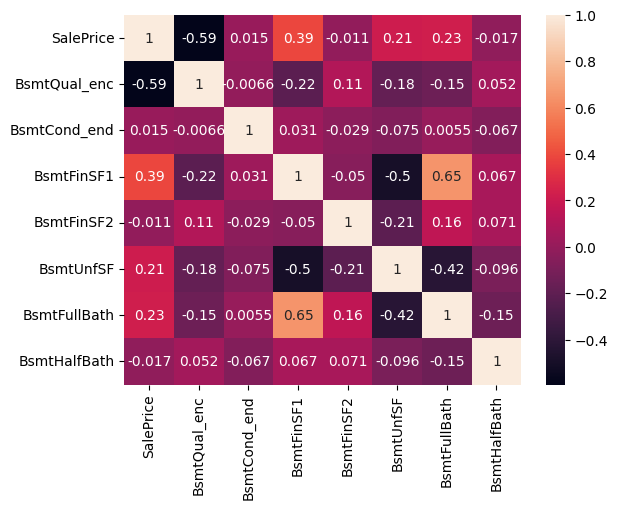

In [ ]:
sns.heatmap(df[['SalePrice', 'BsmtQual_enc', 'BsmtCond_end', u
                               'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'BsmtFllBath', 'BsmtHalfBath']].corr(), annot=True)

In [67]:
df['LotFrontage_filled'] = df['LotFrontage'].fillna(df['LotFrontage'].mean())

In [69]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, root_mean_squared_error

X = df[['BsmtQual_enc', 'BsmtFinSF1', 'LotFrontage_filled', 'LotArea']]
y = df['SalePrice']

model = LinearRegression()
model.fit(X, y)

y_pred = model.predict(X)

print('R2: ', r2_score(y, y_pred))
print('mean_absolute_error: ', mean_absolute_error(y, y_pred))
print('mean_squared_error: ', mean_squared_error(y, y_pred))
print('root_mean_squared_error: ', root_mean_squared_error(y, y_pred))

R2:  0.4807047777135989
mean_absolute_error:  38552.21548681878
mean_squared_error:  3275085180.3423014
root_mean_squared_error:  57228.359930565035


In [70]:
df['SalePrice'].mean()

np.float64(180921.19589041095)

In [71]:
57228/180921

0.3163148556552307